<a href="https://colab.research.google.com/github/EmilioCarson/ti2006b-Emilio/blob/main/notebooks/03_colab_bridge.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Activity 3: Colab–VS Code Bridge
**Author:** Emilio Alvarado Carson (A01751864) · TI2006B

**Question:** In a small synthetic sample of creatures, does the average attack value differ between types?

**Data provenance:** The data are **synthetic**. They are generated inside this notebook with NumPy using a fixed random seed (`42`). No personal, private or external files are used, and no Drive folder is mounted.

**Expected output:** A table with the count and mean attack per type, and a bar chart comparing those means.

## 1. Setup
Prints the Python version and imports the only packages needed. pandas, NumPy and matplotlib come preinstalled in Colab and in the `ti2006b-workbench` conda environment, so nothing else needs to be installed.

In [ ]:
import sys
import platform

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("pandas:", pd.__version__, "| numpy:", np.__version__)

Python: 3.13.18
Platform: Linux-6.6.159+-x86_64-with-glibc2.39
pandas: 2.2.3 | numpy: 2.4.6


## 2. Synthetic data
Creates 60 synthetic records with a fixed seed so every run produces the same numbers.

In [ ]:
rng = np.random.default_rng(42)

types = ["Fire", "Water", "Grass"]
mean_attack = {"Fire": 80, "Water": 70, "Grass": 65}

rows = []
for t in types:
    for value in rng.normal(loc=mean_attack[t], scale=10, size=20):
        rows.append({"type": t, "attack": round(float(value), 1)})

df = pd.DataFrame(rows)
print(df.shape)
df.head()

(60, 2)


,type,attack
0,Fire,83.0
1,Fire,69.6
2,Fire,87.5
3,Fire,89.4
4,Fire,60.5


## 3. Analysis

In [ ]:
summary = (
    df.groupby("type")["attack"]
      .agg(count="count", mean="mean", std="std")
      .round(1)
      .sort_values("mean", ascending=False)
)
summary

,count,mean,std
type,,,
Fire,20,79.7,8.7
Water,20,71.1,7.9
Grass,20,66.2,7.2


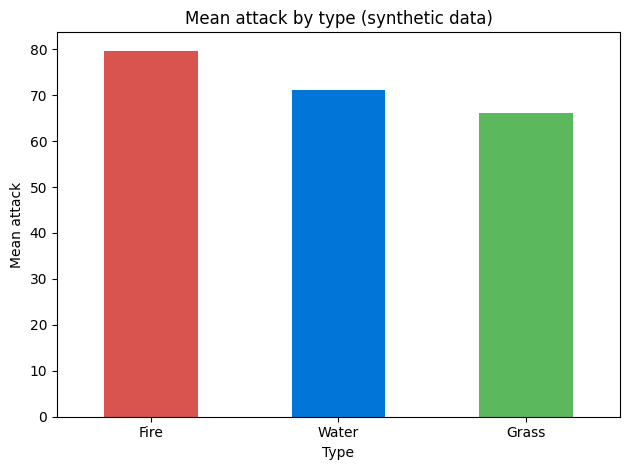

In [ ]:
ax = summary["mean"].plot(kind="bar", color=["#d9534f", "#0275d8", "#5cb85c"], rot=0)
ax.set_title("Mean attack by type (synthetic data)")
ax.set_xlabel("Type")
ax.set_ylabel("Mean attack")
plt.tight_layout()
plt.show()

## 4. Conclusion
In this synthetic sample, **Fire** has the highest mean attack, followed by **Water** and **Grass**. Because the data were generated with known means, the result mainly confirms that the pipeline (setup → data → analysis → chart) runs correctly from a clean session. It says nothing about real-world data.

**Reproducibility notes:** every variable is created inside this notebook; the random seed is fixed; there are no local file paths; and the only dependencies are pandas, NumPy and matplotlib.